# SNR for nearby galaxies


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from snr_average import average_snr, redshift_to_luminosity_distance

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True

galaxies_bhs_df = pd.read_csv("galaxies_bhs_with_coordinates.csv")
galaxies_bhs_df = galaxies_bhs_df[0:1]

display(galaxies_bhs_df.head())
galaxies_bhs_df.info()


,name,z,m1,reference,ra_deg,dec_deg,ra_hms,dec_dms,coordinate_epoch,coordinate_status
0,IMBH 100Mpc,0.023,8200.0,Experiment,NaN,NaN,NaN,NaN,J2000,not uniquely defined


<class 'pandas.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               1 non-null      str    
 1   z                  1 non-null      float64
 2   m1                 1 non-null      float64
 3   reference          1 non-null      str    
 4   ra_deg             0 non-null      float64
 5   dec_deg            0 non-null      float64
 6   ra_hms             0 non-null      str    
 7   dec_dms            0 non-null      str    
 8   coordinate_epoch   1 non-null      str    
 9   coordinate_status  1 non-null      str    
dtypes: float64(4), str(6)
memory usage: 212.0 bytes


## Physical and numerical setup

We keep cosmology/instrument assumptions fixed and vary only $T_{\mathrm{pl}}$ and $m_2$.

Notes:
- `Tobs=4.5` in `average_snr` implies $T_{\mathrm{obs}}=4.5$ years of observation.
- `z=1.86e-6` is approximately the distance to the galactic center in redshift. Redshift is a nice variable because when going to cosmological distances it affects the source-frame detector-frame relation of masses.

In [12]:
# Fixed primary and orbital settings
a = 0.0
ef = 0.0

# Secondary masses: WD, NS, BH, BH
m2_grid = np.geomspace(0.6, 100.0, 20)
# Main plunge-time grid (years) starting from the plunging EMRIs within the LISA mission up to early EMRIs
tpl_grid = np.geomspace(4.5, 1e5, 20)
tobs = 4.5 # years

# SNR settings
psd = 'LISA'
num_freq = 100_000
num_samples = 1  # deterministic default-angle configuration in snr_average.average_snr
seed = 2601

In [13]:
def safe_average_snr(m1, m2, a, tpl, ef, z, psd='LISA', num_freq=50_000, num_samples=1, seed=2601, tobs=None):
    """Return mean SNR or np.nan if FEW integration/waveform generation fails."""

    try:
        snrs, _ = average_snr(
            m1=m1,
            m2=m2,
            a=a,
            Tpl=tpl,
            ef=ef,
            z=z,
            Tobs=tobs,
            psd=psd,
            num_freq=num_freq,
            num_samples=num_samples,
            seed=seed,
            pool=None,
        )
        val = float(np.mean(snrs))
        if not np.isfinite(val):
            return np.nan
        return val
    except Exception:
        return np.nan

In [15]:
for index, row in galaxies_bhs_df.iterrows():
    label = row['name']
    m1 = row['m1']
    z = row['z']
    snr_grid = np.zeros((len(m2_grid), len(tpl_grid)))
    for i, m2 in enumerate(m2_grid):
        print(f"Computing SNR for m1={m1}, m2={m2}, a={a}, ef={ef}, z={z}")
        for j, tpl in enumerate(tpl_grid):
            print(f"Computing SNR for Tpl={tpl} years")
            snr = safe_average_snr(
                m1=m1,
                m2=m2,
                a=a,
                tpl=float(tpl),
                ef=ef,
                z=z,
                psd=psd,
                num_freq=num_freq,
                num_samples=num_samples,
                seed=seed,
                tobs=tobs,  # if tobs=None, then Tobs=Tpl inside average_snr
            )
            snr_grid[i, j] = snr

Computing SNR for m1=8200.0, m2=0.6, a=0.0, ef=0.0, z=0.023
Computing SNR for Tpl=4.5 years
Frequency range 2 fphi: 0.016639902457645656 - 0.5235228879862392 Hz
Computing SNR for Tpl=7.620628709090531 years
Frequency range 2 fphi: 0.013669216633623723 - 0.019071829323004285 Hz
Computing SNR for Tpl=12.905329315958847 years
Frequency range 2 fphi: 0.01122532058340332 - 0.013177630992231066 Hz
Computing SNR for Tpl=21.85482735232525 years
Frequency range 2 fphi: 0.009216193411011228 - 0.01004723572405902 Hz
Computing SNR for Tpl=37.010561056299274 years
Frequency range 2 fphi: 0.007565353520067293 - 0.007942017361064292 Hz
Computing SNR for Tpl=62.67638758337383 years
Frequency range 2 fphi: 0.006209439578108935 - 0.006385382234929471 Hz
Computing SNR for Tpl=106.14077302220967 years
Frequency range 2 fphi: 0.005096087656200654 - 0.005179589514780818 Hz
Computing SNR for Tpl=179.74653824402517 years
Frequency range 2 fphi: 0.00418210222351038 - 0.0042220823022984634 Hz
Computing SNR for 

[  0.6          0.78539957   1.02808747   1.34576576   1.76160641
   2.30594152   3.0184758    3.95118264   5.17209524   6.77026895
   8.86227718  11.60071445  15.18532688  19.87758196  26.01974048
  34.05982157  44.58428193  58.36079298  76.39423603 100.        ]
[  0.52442278   0.68646904   0.89858748   1.17625036   1.53971088
   2.01548043   2.63826243   3.45348363   4.52060759   5.91747208
   7.74596669  10.13946483  13.27255217  17.37376124  22.74224096
  29.76957706  38.96835495  51.0095486   66.77146242  87.40379627
 114.41150644]


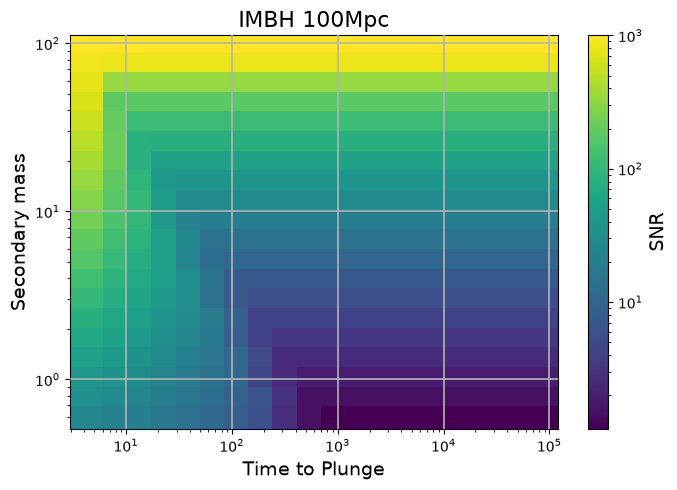

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


fig, ax = plt.subplots(figsize=(7, 5))

mesh = ax.pcolormesh(
    tpl_grid,
    m2_grid,
    snr_grid,
    shading="auto",
    cmap="viridis",
    norm=LogNorm(vmin=np.nanmin(snr_grid), vmax=np.nanmax(snr_grid)),
)


ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Time to Plunge", fontsize=14)
ax.set_ylabel("Secondary mass", fontsize=14)
ax.set_title("IMBH 100Mpc", fontsize=16)

# Grid lines on major ticks
ax.grid(True, which="major", color="0.7", linewidth=1.2)
ax.set_axisbelow(False)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("SNR", fontsize=14)

plt.tight_layout()
plt.show()


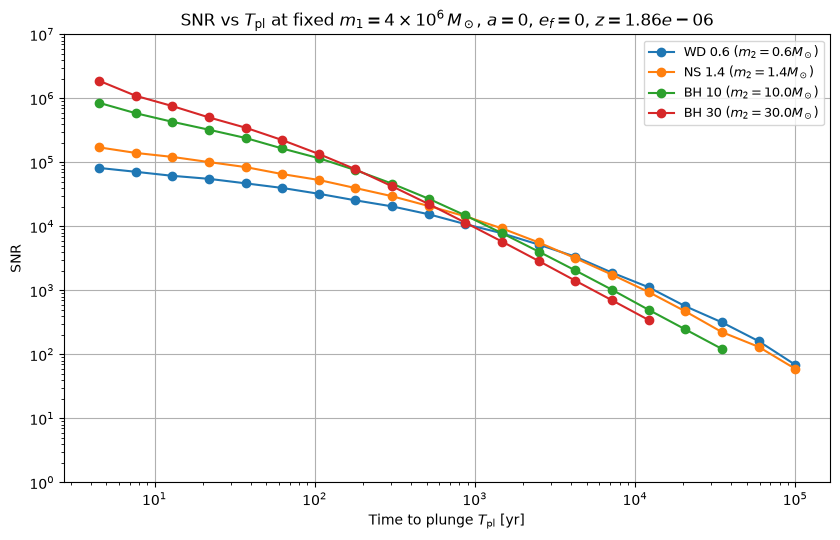

In [7]:
plt.figure(figsize=(8.5, 5.5))
for label, m2 in m2_map.items():
    sub = scan_df[scan_df['label'] == label].sort_values('Tpl_yr')
    plt.loglog(sub['Tpl_yr'], sub['SNR'], marker='o', label=f'{label} ($m_2={m2}M_\odot$)')

# plt.axhline(20, color='k', ls='--', lw=1, alpha=0.6, label='SNR=20')
plt.xlabel(r'Time to plunge $T_{\mathrm{pl}}$ [yr]')
plt.ylabel('SNR')
plt.title(r'SNR vs $T_{\mathrm{pl}}$ at fixed $m_1=4\times10^6\,M_\odot$, $a=0$, $e_f=0$, ' + f'$z={z}$')
plt.legend(fontsize=9)
plt.tight_layout()
plt.ylim(1, 1e7)
plt.show()

## Limitations (important)

1) In this pipeline, initial conditions are obtained by integrating from near separatrix and then integrating backward for a requested plunge time (`get_initial_conditions` in `snr_average.py`). For very large $T_{\mathrm{pl}}$ and/or large secondary masses, this can fail or become numerically unreliable because the backward integration goes only up to regions where FEW/flux are computed.

2) The SNR can suddenly drop if the source is out of band

3) The `num_freq` controls how many frequency points the computation is using, sometimes is good to check that this is not affecting the results